# Введение в Machine Learning
 Практические задания на основе набора данных Iris и Intel® oneAPI AI Analytics Toolkit (AI Kit).

### Student: Covaliuc Stanislav
### Group: IASD 2602 R

### Упражнение 1: Загрузка и первичный анализ данных
    Используя библиотеки `pandas` и `numpy`, загрузите файл `Iris_Data.csv` из директории `data`. Выведите на экран:
    - Общее количество строк.
    - Имена всех колонок.
    - Типы данных для каждой колонки.

In [88]:
import os
import numpy as numpy
import pandas as panda
import matplotlib.pyplot as pyplot
import seaborn as sns

path = [ 'data']



datapath = os.sep.join(path + ['Iris.csv'])
data = panda.read_csv(datapath)

print('Rows in CSV: ', data.shape[0])
print('all names columns: \n', data.columns.tolist())
print('types of rows: \n', data.dtypes)

Rows in CSV:  150
all names columns: 
 ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
types of rows: 
 Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


### Упражнение 2: Очистка и преобразование текстовых данных
    Исследуйте значения в колонке `species`.
    Обратите внимание, что все они начинаются с префикса `Iris-`.
    Напишите код для удаления этого префикса во всех строках (чтобы осталось только `setosa`, `versicolor`, `virginica`).

In [89]:
data['species'] = data.Species.str.replace('Iris-', '')

print(data['species'])

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: str


### Упражнение 3: Описательная статистика и размах (range)
    Используя метод `describe()`,
    создайте новую строку в таблице под названием `range`,
    которая вычисляет разницу между максимальным
    и минимальным значением для каждого числового столбца.

In [90]:
dataDescribe = data.describe()

dataDescribe.loc['range'] = dataDescribe.loc['max'] - dataDescribe.loc['min']

fields = ['min', 'max', 'range']

dataDescribe = dataDescribe.loc[fields]

dataDescribe


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
min,1.0,4.3,2.0,1.0,0.1
max,150.0,7.9,4.4,6.9,2.5
range,149.0,3.6,2.4,5.9,2.4


### Упражнение 4: Группировка данных по видам (Среднее и Медиана)
    "Сгруппируйте набор данных по колонке `species`
    и одновременно примените функции **среднего** (`mean`)
    и **медианы** (`median`) ко всем числовым колонкам.

In [91]:
num_cols = data.select_dtypes(include='number').columns.drop('Id')

data.groupby('species')[num_cols].agg(['mean', 'median'])

SepalLengthCm        SepalWidthCm        PetalLengthCm         \
                    mean median         mean median          mean median   
species                                                                    
setosa             5.006    5.0        3.418    3.4         1.464   1.50   
versicolor         5.936    5.9        2.770    2.8         4.260   4.35   
virginica          6.588    6.5        2.974    3.0         5.552   5.55   

           PetalWidthCm         
                   mean median  
species                         
setosa            0.244    0.2  
versicolor        1.326    1.3  
virginica         2.026    2.0

### Упражнение 5: Расширенная агрегация с помощью словаря
    Используя метод `agg()` для сгруппированных данных,
    примените следующие правила: для `sepal_length`, `sepal_width` и `petal_width`
    вычислите среднее и медиану, а для `petal_length` — только максимальное значение (`max`).

In [92]:
fields = {
    'SepalLengthCm': ['mean', 'median'],
    'SepalWidthCm': ['mean', 'median'],
    'PetalWidthCm': ['mean', 'median'],
    'PetalLengthCm': 'max'
}

data.groupby('species').agg(fields)


SepalLengthCm        SepalWidthCm        PetalWidthCm         \
                    mean median         mean median         mean median   
species                                                                   
setosa             5.006    5.0        3.418    3.4        0.244    0.2   
versicolor         5.936    5.9        2.770    2.8        1.326    1.3   
virginica          6.588    6.5        2.974    3.0        2.026    2.0   

           PetalLengthCm  
                     max  
species                   
setosa               1.9  
versicolor           5.1  
virginica            6.9

### Упражнение 6: Визуализация данных с помощью Matplotlib
    Импортируйте `matplotlib.pyplot`
    и постройте диаграмму рассеяния (scatter plot),
    отражающую зависимость `sepal_length` (ось X) от `sepal_width` (ось Y).
    Добавьте подписи осей и заголовок.

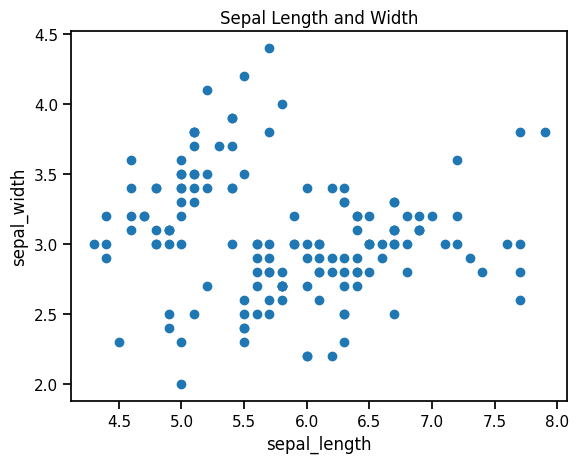

In [93]:

plot = pyplot.axes()

plot.scatter(data.SepalLengthCm, data.SepalWidthCm)

plot.set(
    xlabel='sepal_length',
    ylabel='sepal_width',
    title='Sepal Length and Width'
)

pyplot.show()

### Упражнение 7: Подсчет частоты видов
    "Используйте специальный метод Pandas,
    чтобы узнать точное количество записей
    для каждого отдельного вида в очищенном наборе данных.

In [94]:
data['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Упражнение 8: Ускорение Scikit-learn с помощью Intel® Extension
    Напишите строки кода, которые необходимо выполнить сразу
    после импорта библиотеки `sklearn` для включения оптимизации oneDAL.

**После испорта библиотеки нужно выполнить следующий код:**

```python
from sklearnex import patch_skrearn
patch_sklearn()
```

### Упражнение 9: Фреймворки в Machine Learning
    Основываясь на вводных материалах, объясните,
    почему фреймворки — это больше, чем просто библиотеки,
    и какую материальную пользу приносит оптимизация гиперпараметров.

#### Фреймворки это готовая структура которая помогает в работе с ML, библиотека в свою очередь это просто готовые какие то функции для ускорения работы, а не готовые решения.

## Фреймворк помогает с точностью модели, разработчик может экономить время, а также выделенные ресурсы

### Упражнение 10: Предварительные требования курса
    Перечислите как минимум три базовых направления
    (в математике и программировании),
    необходимых для успешного прохождения курса по Machine Learning.


#### Для работы с машиным обучением необходимы следующие навыки:
1. Линейная алгебра - она помогает строить ML при помощи векторов, матриц
2. Математический анализ - Служит для работы с данными на которой можно обучить модель
3. Теория вероятности и статистика - относится также к обучении модели например чтоб она могла что то предугадать
4. Python - современное решения для ML так как содержит много хороших библиотек
5. Библиотеки такие как Numpy, matplotlib, pandas для работы с данными и также их визуализацией

## Упражнение 11: Продвинутая визуализация распределений с Matplotlib (Гистограммы)
    Используя Matplotlib, постройте фигуру с двумя подграфиками (subplots)
    рядом друг с другом (1 строка, 2 колонки):,
    - На первом графике отобразите гистограмму распределения для `petal_length`.,
    - На втором графике отобразите гистограмму распределения для `petal_width`.,
    Добавьте заголовки и подписи к осям для каждого графика.

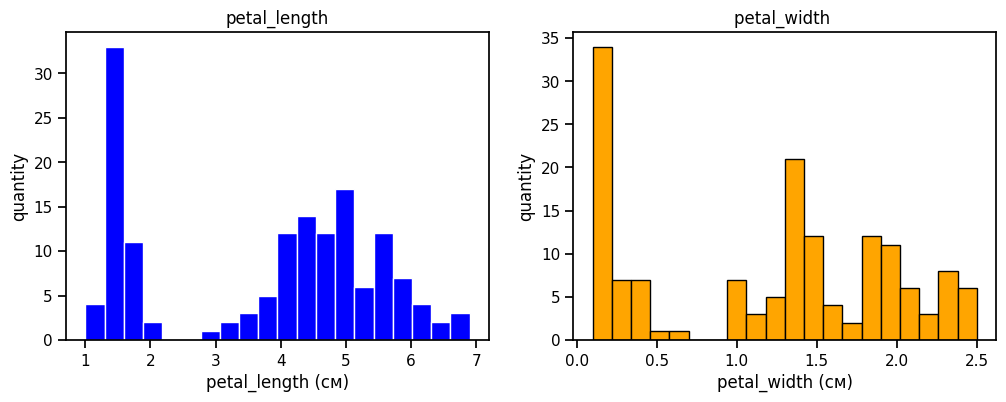

In [95]:

fig, axes = pyplot.subplots(1, 2, figsize=(12, 4))

# Гистограмма длины лепестка
axes[0].hist(data['PetalLengthCm'], bins=20, color='blue', edgecolor='white')
axes[0].set_title('petal_length')
axes[0].set_xlabel('petal_length (см)')
axes[0].set_ylabel('quantity')

# Гистограмма ширины лепестка
axes[1].hist(data['PetalWidthCm'], bins=20, color='orange', edgecolor='black')
axes[1].set_title('petal_width ')
axes[1].set_xlabel('petal_width (см)')
axes[1].set_ylabel('quantity')

pyplot.show()

### Упражнение 12: Исследование данных с помощью Seaborn (Pairplot)
    Импортируйте библиотеку `seaborn`
    и постройте парную матрицу графиков (`sns.pairplot`)
    для всего набора данных Iris,
    раскрасив точки в зависимости от вида растения (`species`).

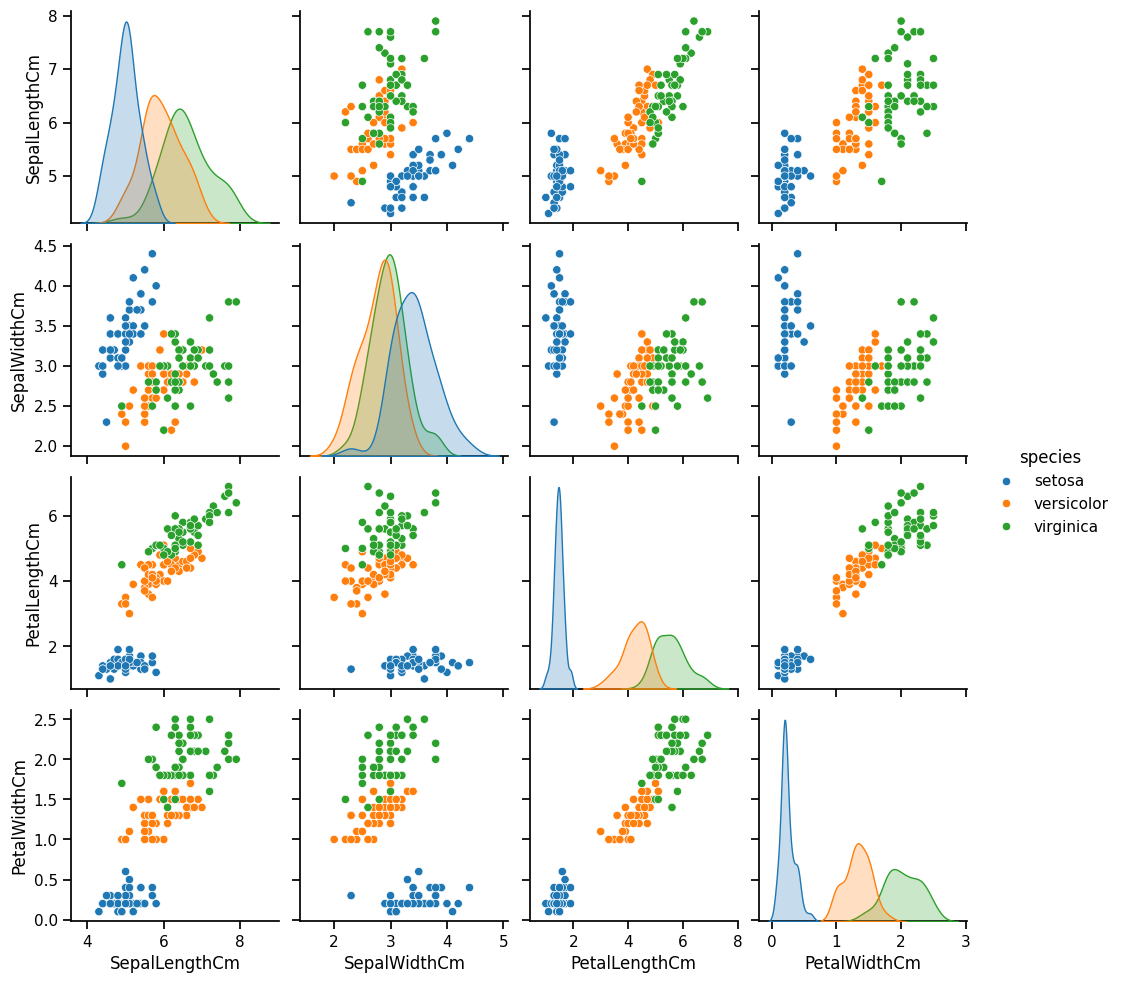

In [96]:
sns.set_context('notebook')

sns.pairplot(data.drop(columns=['Id']), hue='species')
pyplot.show()

### Упражнение 13: Анализ выбросов через Boxplot (Seaborn)
    Используя библиотеку Seaborn, постройте график «ящик с усами» (`sns.boxplot`),
    чтобы сравнить распределение длины лепестков (`petal_length`) для каждого отдельного вида (`species`).

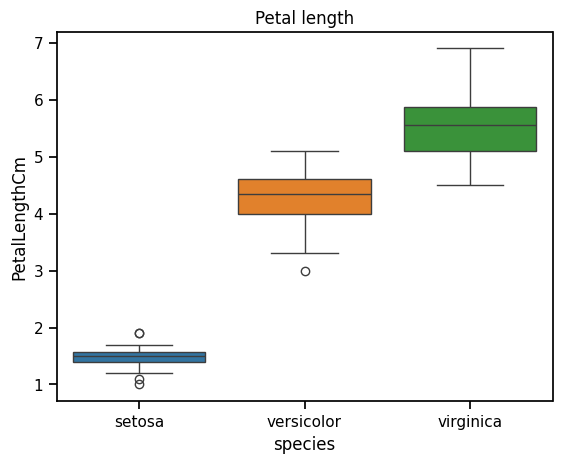

In [97]:
sns.boxplot(data, x='species', y='PetalLengthCm', hue='species')


pyplot.title('Petal length')
pyplot.show()

### Упражнение 14: Тепловая карта корреляций (Seaborn Heatmap)
    Вычислите корреляционную матрицу числовых признаков
    с помощью метода `corr()`, а затем визуализируйте её в виде тепловой карты (`sns.heatmap`),
    включив отображение числовых значений внутри ячеек (`annot=True`).

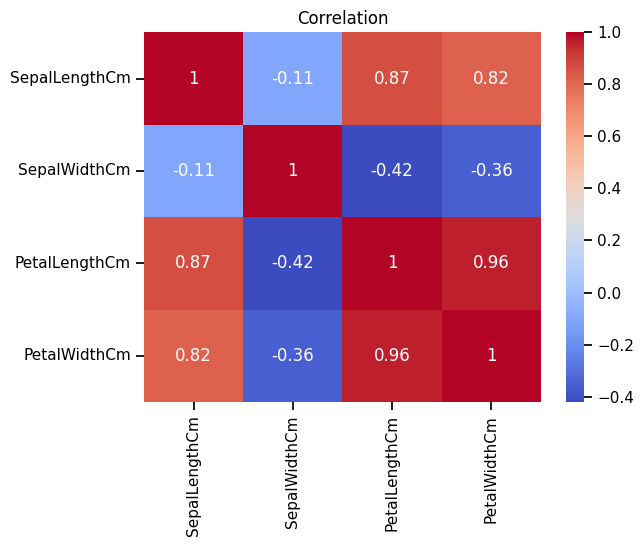

In [98]:
cols = data.select_dtypes(include='number').columns.drop('Id')

corr_data = data[cols].corr()

sns.heatmap(corr_data, annot=True, cmap='coolwarm')


pyplot.title('Correlation')
pyplot.show()